In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:\\Users\\niraj\\OneDrive\\Desktop\\dataset\\indian car dataset\\indian_car_sales.csv")
print(df.head())

      Make   Model       Variant  EX- Showroom Price  Displacement  Cylinders  \
0  Hyundai  Santro        Era Mt              429990          1086          4   
1  Hyundai  Santro      Magna Mt              503990          1086          4   
2  Hyundai  Santro  Magna Mt Cng              547990          1086          4   
3  Hyundai  Santro     Magna Amt              530990          1086          4   
4  Hyundai  Santro     Sportz Mt              512990          1086          4   

   Fuel_Tank_Capacity Fuel_Type  Height  Length  Width  Body_Type  \
0                35.0    Petrol    1560  3610.0   1645  Hatchback   
1                35.0    Petrol    1560  3610.0   1645  Hatchback   
2                35.0       CNG    1560  3610.0   1645  Hatchback   
3                35.0    Petrol    1560  3610.0   1645  Hatchback   
4                35.0    Petrol    1560  3610.0   1645  Hatchback   

   Seating_Capacity    Type  Power.1  Torque.1  Column1 Category  Unnamed: 18  
0                 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Load data
df = pd.read_csv("C:\\Users\\niraj\\OneDrive\\Desktop\\dataset\\indian car dataset\\indian_car_sales.csv")

# Basic inspection
print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nInfo:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Shape: (1276, 19)

First 5 rows:
      Make   Model       Variant  EX- Showroom Price  Displacement  Cylinders  Fuel_Tank_Capacity Fuel_Type  Height  Length  Width  Body_Type  Seating_Capacity    Type  Power.1  Torque.1  Column1  \
0  Hyundai  Santro        Era Mt              429990          1086          4                35.0    Petrol    1560  3610.0   1645  Hatchback                 5  Manual     69.0     99.04      4.3   
1  Hyundai  Santro      Magna Mt              503990          1086          4                35.0    Petrol    1560  3610.0   1645  Hatchback                 5  Manual     69.0     99.04      5.0   
2  Hyundai  Santro  Magna Mt Cng              547990          1086          4                35.0       CNG    1560  3610.0   1645  Hatchback                 5  Manual     59.0     99.04      5.5   
3  Hyundai  Santro     Magna Amt              530990          1086          4                35.0    Petrol    1560  3610.0   1645  Hatchback                 5     AMT    

In [7]:
make_col = "Make"
price_col = "EX- Showroom Price"

make_total = df.groupby(make_col)[price_col].sum().sort_values(ascending=False)

print("Total Ex-Showroom Price by Make:")
print(make_total)

Total Ex-Showroom Price by Make:
Make
Mercedes-Benz       1155616854
Lamborghini          507700950
Land Rover Rover     444324575
Bugatti              404298334
Ferrari              342979965
Bmw                  305480000
Bentley              243395126
Jaguar               230219067
Audi                 224453350
Porsche              214844000
Lexus                150153000
Maserati             141272009
Toyota               135550600
Mahindra             131581325
Hyundai              128371951
Aston Martin         108802326
Volvo                105025500
Maruti Suzuki        102632446
Tata                  93711457
Jeep                  89695986
Skoda                 84876817
Land Rover            84570798
Honda                 77192740
Nissan                49165706
Ford                  48325714
Volkswagen            44945400
Mini                  37920000
Kia                   35724000
Renault               28839879
Mitsubishi            24193350
Mg                    20934000
F

In [8]:
make_col = "Make"
price_col = "EX- Showroom Price"

make_total = (
    df.groupby(make_col)[price_col]
    .agg(Count="count", Total_Ex_Showroom_Price="sum")
    .sort_values("Total_Ex_Showroom_Price", ascending=False)
    .reset_index()
)

print("Total Ex-Showroom Price by Make:")
print(make_total.to_string(index=False))

Total Ex-Showroom Price by Make:
            Make  Count  Total_Ex_Showroom_Price
   Mercedes-Benz     75               1155616854
     Lamborghini     13                507700950
Land Rover Rover     27                444324575
         Bugatti      2                404298334
         Ferrari      8                342979965
             Bmw     37                305480000
         Bentley      6                243395126
          Jaguar     22                230219067
            Audi     31                224453350
         Porsche     14                214844000
           Lexus     10                150153000
        Maserati      9                141272009
          Toyota     82                135550600
        Mahindra    119                131581325
         Hyundai    130                128371951
    Aston Martin      3                108802326
           Volvo     18                105025500
   Maruti Suzuki    149                102632446
            Tata    100             

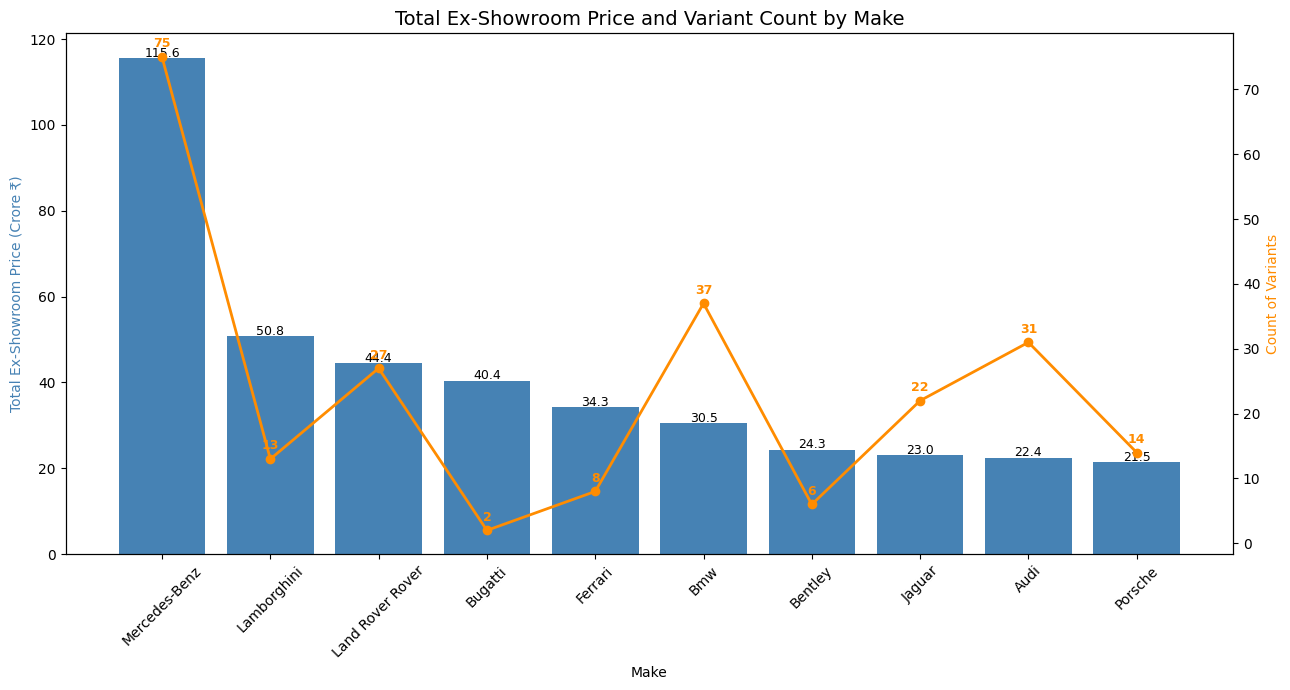

In [10]:
import os

# Convert to Crore so the numbers are easy to read (1 Crore = 10,000,000)
make_total["Total_Cr"] = make_total["Total_Ex_Showroom_Price"] / 1e7

top = make_total.head(10)          # change 10 to show more or fewer makes

os.makedirs("images", exist_ok=True)

fig, ax1 = plt.subplots(figsize=(13, 7))

# Bars = total ex-showroom price
bars = ax1.bar(top["Make"], top["Total_Cr"], color="steelblue", label="Total Price (Cr)")
ax1.set_ylabel("Total Ex-Showroom Price (Crore ₹)", color="steelblue")
ax1.set_xlabel("Make")
ax1.tick_params(axis="x", rotation=45)

# Write the total on top of each bar
for bar, total in zip(bars, top["Total_Cr"]):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
             f"{total:.1f}", ha="center", fontsize=9)

# Line = count of variants (second y-axis)
ax2 = ax1.twinx()
ax2.plot(top["Make"], top["Count"], color="darkorange", marker="o",
         linewidth=2, label="Count")
ax2.set_ylabel("Count of Variants", color="darkorange")

# Write the count next to each point
for x, c in zip(top["Make"], top["Count"]):
    ax2.text(x, c + 1.5, str(c), ha="center", color="darkorange", fontsize=9, fontweight="bold")

plt.title("Total Ex-Showroom Price and Variant Count by Make", fontsize=14)
fig.tight_layout()

plt.savefig("images/make_total_and_count.png", dpi=150, bbox_inches="tight")
plt.show()

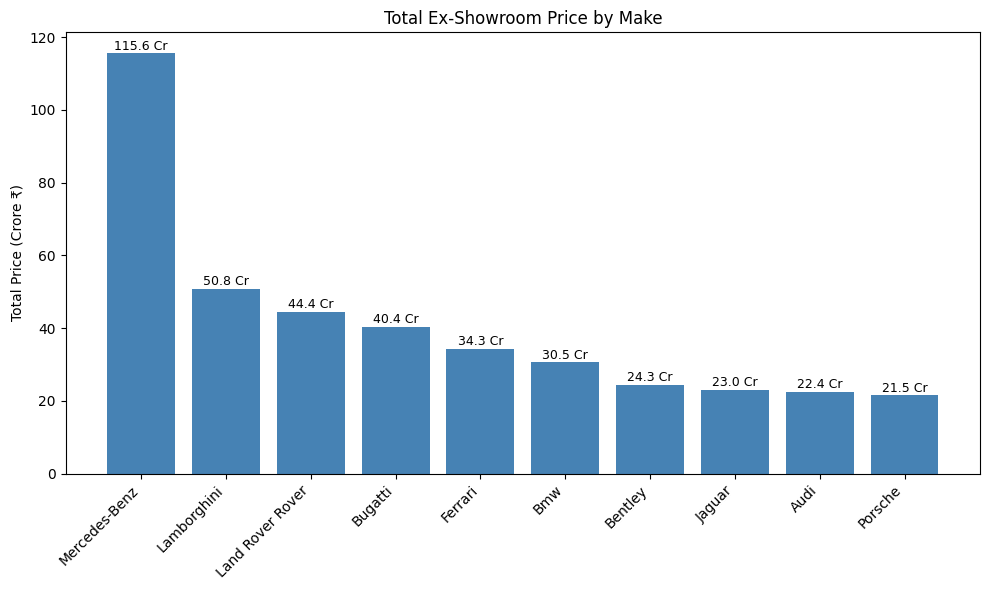

In [14]:
import os

make_total["Total_Cr"] = make_total["Total_Ex_Showroom_Price"] / 1e7   # convert to Crore

top = make_total.head(10)          # only 10 makes, so it stays clean

os.makedirs("images", exist_ok=True)

plt.figure(figsize=(10, 6))
bars = plt.bar(top["Make"], top["Total_Cr"], color="steelblue")

# Write the count on top of each bar
for bar, count in zip(bars, top["Total_Cr"]):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 1,
             f"{count:.1f} Cr",
             ha="center", fontsize=9)

plt.title("Total Ex-Showroom Price by Make")
plt.ylabel("Total Price (Crore ₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("images/make_total_simple.png", dpi=150)
plt.show()

In [15]:
print(df.head(5))

      Make   Model       Variant  EX- Showroom Price  Displacement  Cylinders  Fuel_Tank_Capacity Fuel_Type  Height  Length  Width  Body_Type  Seating_Capacity    Type  Power.1  Torque.1  Column1  \
0  Hyundai  Santro        Era Mt              429990          1086          4                35.0    Petrol    1560  3610.0   1645  Hatchback                 5  Manual     69.0     99.04      4.3   
1  Hyundai  Santro      Magna Mt              503990          1086          4                35.0    Petrol    1560  3610.0   1645  Hatchback                 5  Manual     69.0     99.04      5.0   
2  Hyundai  Santro  Magna Mt Cng              547990          1086          4                35.0       CNG    1560  3610.0   1645  Hatchback                 5  Manual     59.0     99.04      5.5   
3  Hyundai  Santro     Magna Amt              530990          1086          4                35.0    Petrol    1560  3610.0   1645  Hatchback                 5     AMT     69.0     10.10      5.3   
4  Hy

In [20]:
df = df.rename(columns={"Column1": "Ex- Showroom (Lakhs)"})
print(df.columns.tolist())

['Make', 'Model', 'Variant', 'EX- Showroom Price', 'Displacement', 'Cylinders', 'Fuel_Tank_Capacity', 'Fuel_Type', 'Height', 'Length', 'Width', 'Body_Type', 'Seating_Capacity', 'Type', 'Power.1', 'Torque.1', 'Ex- Showroom (Lakhs)', 'Category', 'Unnamed: 18']


In [21]:
df.head(5)

,Make,Model,Variant,EX- Showroom Price,Displacement,Cylinders,Fuel_Tank_Capacity,Fuel_Type,Height,Length,Width,Body_Type,Seating_Capacity,Type,Power.1,Torque.1,Ex- Showroom (Lakhs),Category,Unnamed: 18
0,Hyundai,Santro,Era Mt,429990,1086,4,35.0,Petrol,1560,3610.0,1645,Hatchback,5,Manual,69.0,99.04,4.3,Budget,NaN
1,Hyundai,Santro,Magna Mt,503990,1086,4,35.0,Petrol,1560,3610.0,1645,Hatchback,5,Manual,69.0,99.04,5.0,Budget,NaN
2,Hyundai,Santro,Magna Mt Cng,547990,1086,4,35.0,CNG,1560,3610.0,1645,Hatchback,5,Manual,59.0,99.04,5.5,Budget,NaN
3,Hyundai,Santro,Magna Amt,530990,1086,4,35.0,Petrol,1560,3610.0,1645,Hatchback,5,AMT,69.0,10.10,5.3,Budget,NaN
4,Hyundai,Santro,Sportz Mt,512990,1086,4,35.0,Petrol,1560,3610.0,1645,Hatchback,5,Manual,69.0,10.10,5.1,Budget,NaN


In [26]:
category_col = "Category"
price_col = "EX- Showroom Price"

category_total = df.groupby(category_col)[price_col].sum().sort_values(ascending=False)

print("Total Ex-Showroom Price by Category:")
print(category_total)

Total Ex-Showroom Price by Category:
Category
Luxury       4526291103
Mid-Range     663834917
Premium       442771561
Budget        232284763
Name: EX- Showroom Price, dtype: int64


In [29]:
category_col = "Category"

category_count = df.groupby(category_col).size().sort_values(ascending=False)
print("Count of Cars by Category:")
print(category_count)

Count of Cars by Category:
Category
Mid-Range    538
Budget       386
Luxury       228
Premium      124
dtype: int64


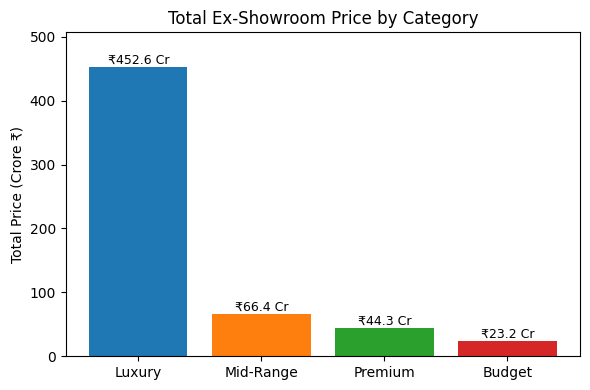

In [28]:
import os

price_col = "EX- Showroom Price"

cat_total = (
    df.groupby("Category")[price_col]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="Total")
)
cat_total["Total_Cr"] = cat_total["Total"] / 1e7   # convert to Crore

os.makedirs("images", exist_ok=True)

plt.figure(figsize=(6, 4))
bars = plt.bar(cat_total["Category"], cat_total["Total_Cr"],
               color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"])

# Write the ex-showroom price on top of each bar
for bar, total in zip(bars, cat_total["Total_Cr"]):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 5,
             f"₹{total:.1f} Cr",
             ha="center", fontsize=9)

plt.title("Total Ex-Showroom Price by Category")
plt.ylabel("Total Price (Crore ₹)")
plt.ylim(0, cat_total["Total_Cr"].max() * 1.12)   # leaves room for the labels
plt.tight_layout()

plt.savefig("images/category_total_price.png", dpi=150)
plt.show()

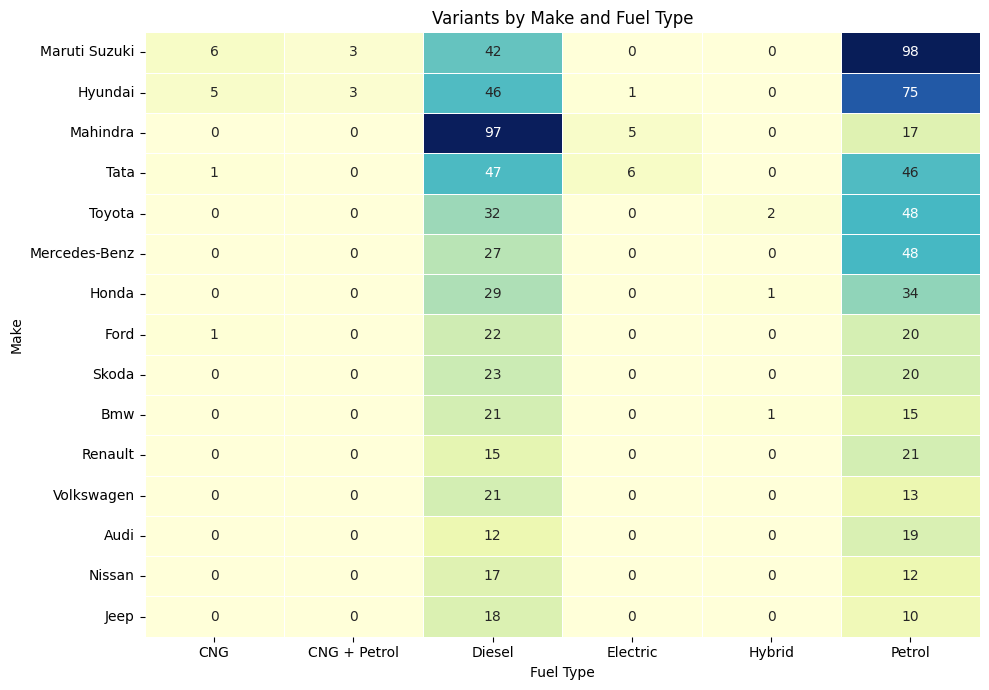

In [45]:
fuel_col = "Fuel_Type"

fuel_table = pd.crosstab(df["Make"], df[fuel_col])
fuel_table["Total"] = fuel_table.sum(axis=1)
fuel_table = fuel_table.sort_values("Total", ascending=False)

import os
os.makedirs("images", exist_ok=True)

data = fuel_table.drop(columns="Total").head(15)

plt.figure(figsize=(10, 7))
sns.heatmap(data, annot=True, fmt="d", cmap="YlGnBu",
            linewidths=0.5, linecolor="white", cbar=False)

plt.title("Variants by Make and Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Make")
plt.tight_layout()
plt.savefig("images/fuel_heatmap_table.png", dpi=150)
plt.show()

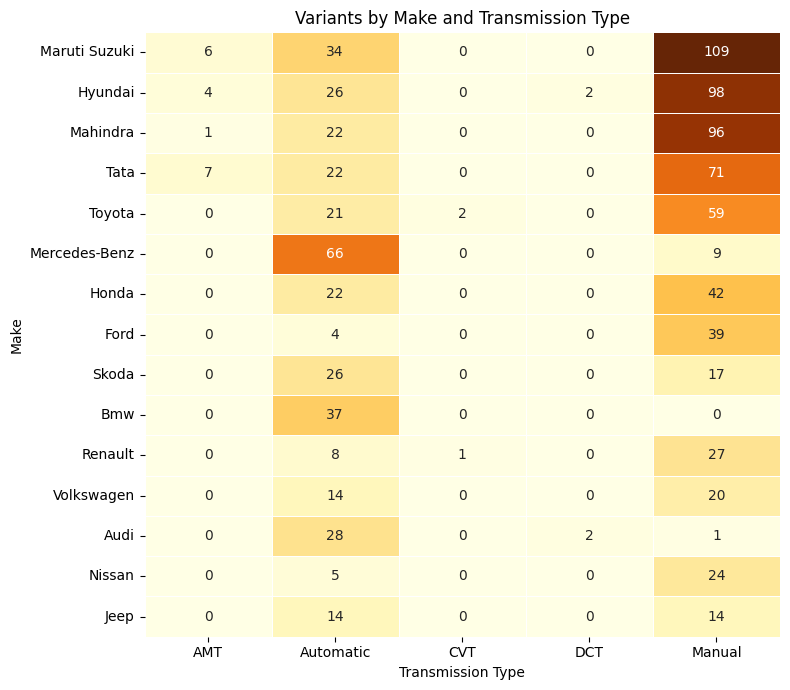

In [44]:
type_col = "Type"

type_table = pd.crosstab(df["Make"], df[type_col])
type_table["Total"] = type_table.sum(axis=1)
type_table = type_table.sort_values("Total", ascending=False)


import os
os.makedirs("images", exist_ok=True)

data = type_table.drop(columns="Total").head(15)

plt.figure(figsize=(8, 7))
sns.heatmap(data, annot=True, fmt="d", cmap="YlOrBr",
            linewidths=0.5, linecolor="white", cbar=False)

plt.title("Variants by Make and Transmission Type")
plt.xlabel("Transmission Type")
plt.ylabel("Make")
plt.tight_layout()
plt.savefig("images/type_by_make.png", dpi=150)
plt.show()